# Plots for normality of the data checks

## Imports

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

## Generate data

In [2]:
MEAN = 0
STDEV = 1
SAMPLE_SIZE = 500

np.random.seed(0)
data = np.random.normal(
    loc=MEAN,
    scale=STDEV,
    size=SAMPLE_SIZE
)

In [3]:
data

array([ 1.76405235,  0.40015721,  0.97873798,  2.2408932 ,  1.86755799,
       -0.97727788,  0.95008842, -0.15135721, -0.10321885,  0.4105985 ,
        0.14404357,  1.45427351,  0.76103773,  0.12167502,  0.44386323,
        0.33367433,  1.49407907, -0.20515826,  0.3130677 , -0.85409574,
       -2.55298982,  0.6536186 ,  0.8644362 , -0.74216502,  2.26975462,
       -1.45436567,  0.04575852, -0.18718385,  1.53277921,  1.46935877,
        0.15494743,  0.37816252, -0.88778575, -1.98079647, -0.34791215,
        0.15634897,  1.23029068,  1.20237985, -0.38732682, -0.30230275,
       -1.04855297, -1.42001794, -1.70627019,  1.9507754 , -0.50965218,
       -0.4380743 , -1.25279536,  0.77749036, -1.61389785, -0.21274028,
       -0.89546656,  0.3869025 , -0.51080514, -1.18063218, -0.02818223,
        0.42833187,  0.06651722,  0.3024719 , -0.63432209, -0.36274117,
       -0.67246045, -0.35955316, -0.81314628, -1.7262826 ,  0.17742614,
       -0.40178094, -1.63019835,  0.46278226, -0.90729836,  0.05

## Plot histogram, pdf and Q-Q plot

### PDF calculation

* PDF is a probability density function, calculated using [scipy](https://docs.scipy.org/doc/scipy-1.18.0/reference/generated/scipy.stats.norm.html#scipy.stats.norm)
* PDF = a known theoretical probability distribution
* It answers the question of:

> "If the data were normally distributed, what would the distribution look like?"

In [4]:
x_vals = np.linspace(min(data), max(data), SAMPLE_SIZE)

In [5]:
pdf_line = stats.norm.pdf(
    x=x_vals,
    loc=np.mean(data),
    scale=np.std(data)
)

### KDE calculation

* KDE - kernel density estimation
* KDE - an estimate of the distribution from your observed data
* Scipy [docs](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gaussian_kde.html)
* It answers the question of:

> "What distribution shape do the data themselves suggest?"

* The KDE is more useful for discovering the shape of an unknown distribution, while the PDF is more useful for checking whether a specific theoretical distribution fits the data.

In [22]:
kde = stats.gaussian_kde(dataset=data)

In [24]:
kde_y_vals = kde(x_vals)

### Quantiles calculation

* [scipy docs](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.probplot.html)

In [34]:
# TODO: add interpretation for QQ shape (banana, s-curve, etc.)

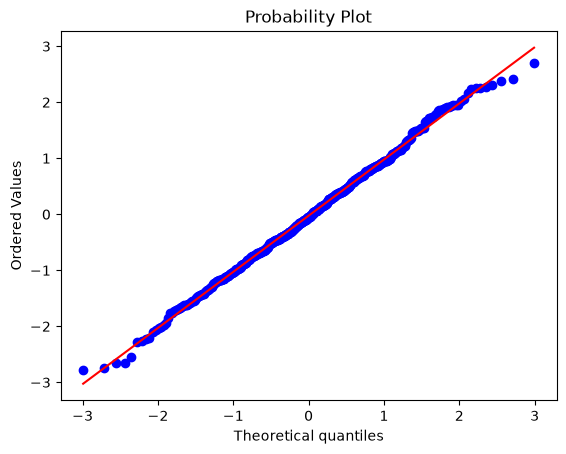

In [6]:
# QQ can be calculated and plotted at the same time (for a quick check):
fig, ax = plt.subplots()
stats.probplot(data, dist="norm", plot=ax);

In [7]:
qq_out = stats.probplot(
    x=data,
    dist="norm",  # defualt anyway
    fit=True,  # default anyway
)

In [8]:
# It returns two elements
len(qq_out)

2

When we unpack the output of the `stats.probplot()` we get:

```
(theoretical_q, ordered_values), (slope, intercept, r) = stats.probplot(data, dist="norm")
```

Where:

* `theoretical_q`: theoretical normal quantiles (the `Xs`)
* `ordered_values`: ordered sample values (the `Ys`)
* `slope`, `intercept`: fitted reference line parameters
* `r`: correlation coefficient used in the fit

In [9]:
# Now I can use all the output values in my custom plot
(theoretical_q, ordered_values), (slope, intercept, r) = stats.probplot(
    x=data,
    dist="norm",  # defualt anyway
    fit=True,  # default anyway
)

### Plot with matplotlib

* The Freedman-Diaconis (fd) rule uses the interquartile range (IQR) to determine bin width and is therefore less sensitive to outliers than methods that rely on the standard deviation (e.g. Scott's rule).


* Once thw width of the bins is known, the number of bins are calculated with: $ \text{bins} = \frac{\max(x) - \min(x)}{h} $

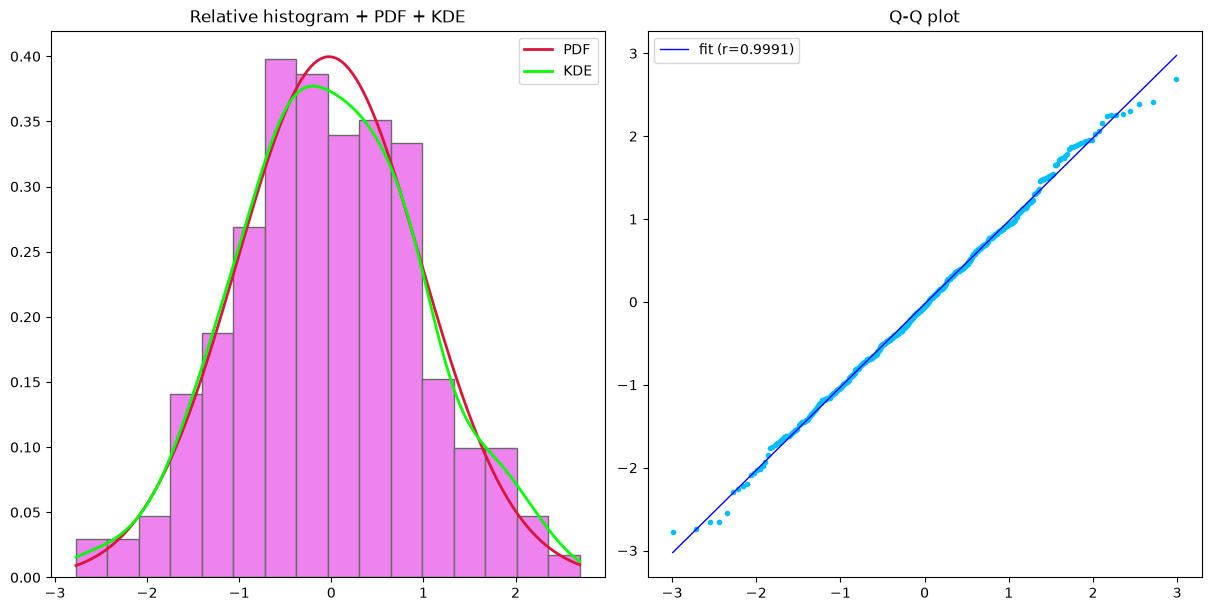

In [ ]:
# TODO: add axis labels to QQ
# TODO: add boxplot

fig, axs = plt.subplot_mosaic(
    figsize=(12,6),
    mosaic=[["hist", "qq"]],
    constrained_layout=True
)

# -- Plot 1.1 ---
axs["hist"].set_title("Relative histogram + PDF + KDE")

axs["hist"].hist(
    data,
    edgecolor="dimgrey",
    facecolor="violet",
    density=True,
    bins="fd"
)

# -- Plot 1.2 - PDF line ---
axs["hist"].plot(
    x_vals,
    pdf_line,
    color="crimson",
    linewidth=2,
    label="PDF"
)

# -- Plot 1.3 - KDE line ---
axs["hist"].plot(
    x_vals,
    kde_y_vals,
    color="lime",
    linewidth=2,
    label="KDE"
)

axs["hist"].legend()

# --- Plot 2.1 - points ---
axs["qq"].set_title("Q-Q plot")

axs["qq"].scatter(
    theoretical_q,
    ordered_values,
    color="deepskyblue",
    marker="."
)

# --- Plot 2.1 - fit line ---
axs["qq"].plot(
    theoretical_q,  # Xs
    slope * theoretical_q + intercept,  # Ys
    color="blue",
    linewidth=1,
    label=f"fit (r={r:.4f})"
)

axs["qq"].legend();


### Plot with Seaborn

#### Histogram + KDE

<Axes: ylabel='Density'>

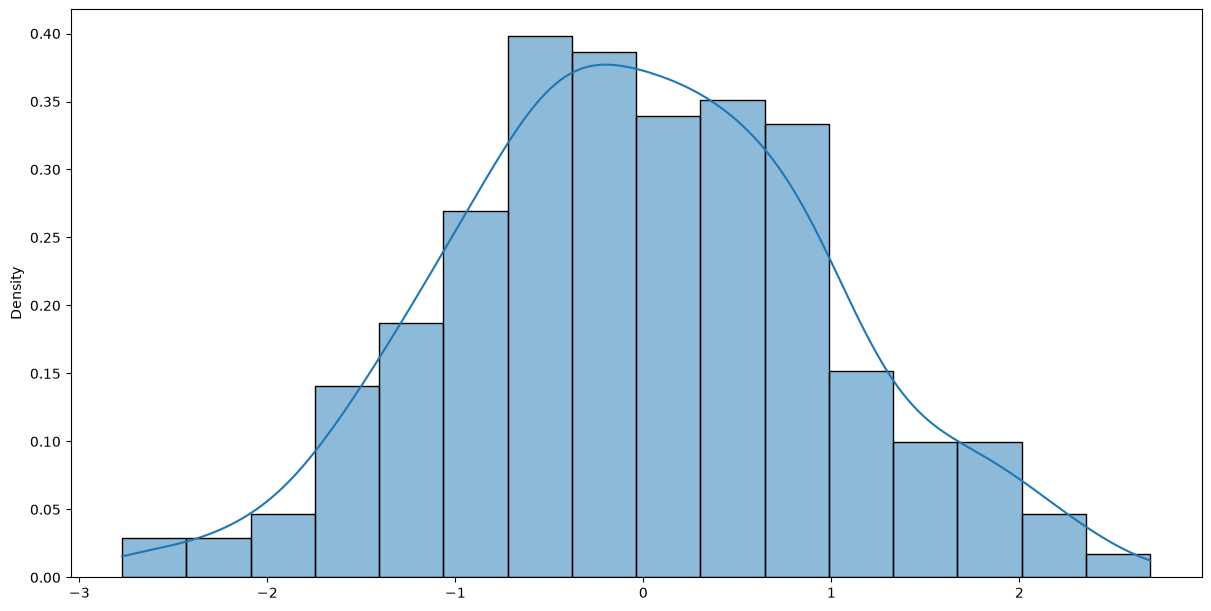

In [21]:
fig, ax = plt.subplots(
    figsize=(12,6),
    constrained_layout=True
)


sns.histplot(
    data,
    bins="fd",
    stat="density",
    kde=True,
    ax=ax
)

#### Histogram + boxplot + QQ

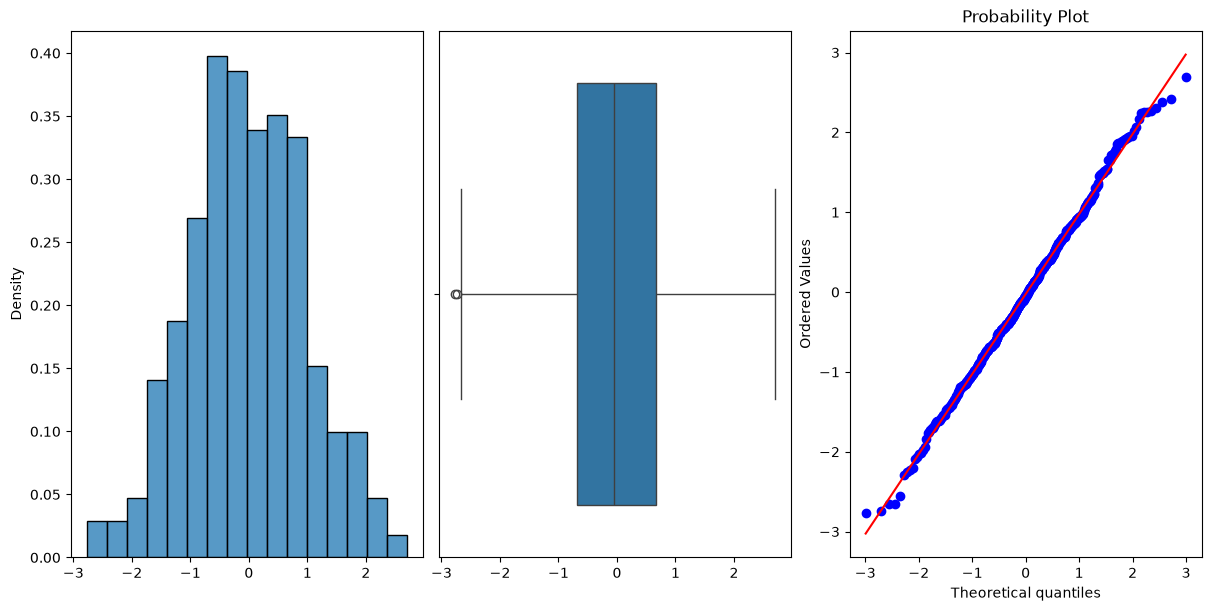

In [33]:
fig, axs = plt.subplots(
    1,3,
    figsize=(12, 6),
    constrained_layout=True
)

sns.histplot(
    data,
    bins="fd",
    stat="density",
    ax=axs[0]
)

sns.boxplot(
    x=data,
    ax=axs[1]
)

stats.probplot(
    data,
    plot=axs[2]
);